In [1]:
# %% 1. Import & baca data
import pandas as pd

data = pd.read_csv(r"C:\Users\s2\Documents\RKI\BRFSS\brfss2023.csv")
print(f"Ukuran awal: {data.shape}")

# %% 2. Filter dulu: hanya DIABETE4 == 1
print(data['DIABETE4'].value_counts(dropna=False))

data = data[data['DIABETE4'] == 1].copy()
data = data.reset_index(drop=True)

print(f"Ukuran setelah filter: {data.shape}")
print(data['DIABETE4'].value_counts())

Ukuran awal: (433323, 350)
DIABETE4
3.0    358706
1.0     59786
4.0     10594
2.0      3253
7.0       683
9.0       296
NaN         5
Name: count, dtype: int64
Ukuran setelah filter: (59786, 350)
DIABETE4
1.0    59786
Name: count, dtype: int64


In [2]:
data

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,DROCDY4_,_RFBING6,_DRNKWK2,_RFDRHV8,_FLSHOT7,_PNEUMO3,_AIDTST4,_RFSEAT2,_RFSEAT3,_DRNKDRV
0,1.0,1.0,3012023,3,1,2023,1100.0,2023000001,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,2.0,2.0,2.0,1.0,1.0,9.0
1,1.0,1.0,1062023,1,6,2023,1100.0,2023000005,2.023000e+09,1.0,...,7.000000e+00,1.0,4.700000e+01,1.0,2.0,1.0,2.0,1.0,1.0,2.0
2,1.0,1.0,1062023,1,6,2023,1100.0,2023000008,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0,1.0,1.0,9.0
3,1.0,1.0,1082023,1,8,2023,1100.0,2023000010,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0,1.0,1.0,9.0
4,1.0,1.0,1062023,1,6,2023,1100.0,2023000020,2.023000e+09,1.0,...,1.000000e+02,1.0,7.000000e+02,1.0,1.0,1.0,2.0,1.0,1.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59781,78.0,12.0,12142023,12,14,2023,1100.0,2023002027,2.023002e+09,NaN,...,1.300000e+01,1.0,1.870000e+02,1.0,NaN,NaN,1.0,1.0,1.0,2.0
59782,78.0,12.0,12112023,12,11,2023,1100.0,2023002029,2.023002e+09,NaN,...,5.397605e-79,1.0,5.397605e-79,1.0,NaN,NaN,2.0,1.0,1.0,9.0
59783,78.0,12.0,12152023,12,15,2023,1100.0,2023002038,2.023002e+09,NaN,...,5.397605e-79,1.0,5.397605e-79,1.0,NaN,NaN,2.0,1.0,1.0,9.0
59784,78.0,12.0,12102023,12,10,2023,1100.0,2023002059,2.023002e+09,NaN,...,5.397605e-79,1.0,5.397605e-79,1.0,2.0,2.0,1.0,1.0,1.0,9.0


In [3]:
# %% 3. Cek missing value (dihitung dari data diabetes saja)
missing = data.isnull().sum()
missing_pct = (missing / len(data)) * 100

missing_df = pd.DataFrame({
    'jumlah_kosong': missing,
    'persen_kosong': missing_pct.round(2)
})
missing_df = (missing_df[missing_df['jumlah_kosong'] > 0]
              .sort_values('persen_kosong', ascending=False))

print(f"Total fitur           : {data.shape[1]}")
print(f"Fitur yang ada kosong : {len(missing_df)}")
print(missing_df.head(20))

Total fitur           : 350
Fitur yang ada kosong : 268
          jumlah_kosong  persen_kosong
WKENDOUT          59786         100.00
SUNPRTCT          59786         100.00
WKDAYOUT          59786         100.00
INDORTAN          59786         100.00
NUMBURN3          59786         100.00
PDIABTS1          59786         100.00
PREDIAB2          59785         100.00
COLGHOUS          59783          99.99
CCLGHOUS          59755          99.95
LNDSXBRT          59754          99.95
LASTSIG4          59743          99.93
CSRVCTL2          59740          99.92
HPVADSHT          59718          99.89
BLDSTFIT          59701          99.86
SDNATES1          59701          99.86
VCLNTES2          59694          99.85
CRVCLCNC          59690          99.84
CRVCLPAP          59690          99.84
CRVCLHPV          59690          99.84
CELSXBRT          59588          99.67


In [4]:
# %% 4. Hapus fitur dengan missing value > 15%
cols_to_drop = missing_pct[missing_pct >= 20].index

print(f"Jumlah fitur yang dihapus: {len(cols_to_drop)}")
print(missing_pct[cols_to_drop].sort_values(ascending=False).head(20))

data = data.drop(columns=cols_to_drop)
print(f"Sisa fitur: {data.shape[1]}")


Jumlah fitur yang dihapus: 218
PDIABTS1    100.000000
NUMBURN3    100.000000
WKENDOUT    100.000000
WKDAYOUT    100.000000
SUNPRTCT    100.000000
INDORTAN    100.000000
PREDIAB2     99.998327
COLGHOUS     99.994982
CCLGHOUS     99.948148
LNDSXBRT     99.946476
LASTSIG4     99.928077
CSRVCTL2     99.923059
HPVADSHT     99.886261
SDNATES1     99.857826
BLDSTFIT     99.857826
VCLNTES2     99.846118
CRVCLPAP     99.839427
CRVCLHPV     99.839427
CRVCLCNC     99.839427
CELSXBRT     99.668819
dtype: float64
Sisa fitur: 132


In [5]:
sisa = data.isnull().sum()
sisa_pct = (sisa / len(data) * 100).round(2)

sisa_df = pd.DataFrame({'jumlah': sisa, 'persen': sisa_pct})
sisa_df = sisa_df[sisa_df['jumlah'] > 0].sort_values('persen', ascending=False)

print(f"Fitur yang masih punya kosong: {len(sisa_df)} dari {data.shape[1]}")
print(sisa_df)

Fitur yang masih punya kosong: 50 dari 132
          jumlah  persen
SHINGLE2   10616   17.76
FALL12MN    6426   10.75
_BMI5       5235    8.76
_BMI5CAT    5235    8.76
WTKG3       4577    7.66
COVIDPO1    3981    6.66
SEATBELT    3824    6.40
HIVTST7     3664    6.13
_AIDTST4    3664    6.13
PNEUVAC4    3543    5.93
FLUSHOT7    3422    5.72
HTIN4       3188    5.33
ALCDAY4     3180    5.32
CHOLMED3    2802    4.69
HTM4        2735    4.57
ECIGNOW2    2653    4.44
_RFCHOL3    2624    4.39
TOLDHI3     2624    4.39
USENOW3     2537    4.24
SMOKE100    2446    4.09
STRFREQ_    2246    3.76
DIFFALON    2178    3.64
DIFFDRES    2053    3.43
DIFFWALK    1949    3.26
DECIDE      1837    3.07
BLIND       1730    2.89
DEAF        1613    2.70
_METSTAT    1539    2.57
_URBSTAT    1539    2.57
HEIGHT3     1418    2.37
WEIGHT2     1288    2.15
_MICHD      1057    1.77
INCOME3      925    1.55
CHILDREN     567    0.95
EMPLOY1      373    0.62
_DRDXAR2     344    0.58
VETERAN3     162    0.27
_MRACE1

In [6]:
data.isna().sum()

_STATE         0
FMONTH         0
IDATE          0
IMONTH         0
IDAY           0
            ... 
_RFDRHV8       0
_AIDTST4    3664
_RFSEAT2       0
_RFSEAT3       0
_DRNKDRV       0
Length: 132, dtype: int64

In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 59786 entries, 0 to 59785
Columns: 132 entries, _STATE to _DRNKDRV
dtypes: float64(127), int64(5)
memory usage: 60.2 MB


In [8]:
import pandas as pd

pd.set_option("display.max_rows", 200)

# 1. value_counts semua kolom, NaN ikut dihitung
for col in data.columns:
    print(f"\n=== {col} | unik: {data[col].nunique()} | NaN: {data[col].isna().sum()} ===")
    print(data[col].value_counts(dropna=False).head(15))


=== _STATE | unik: 52 | NaN: 0 ===
_STATE
53.0    2945
24.0    2607
39.0    2241
12.0    2122
36.0    2039
27.0    1963
55.0    1963
45.0    1793
18.0    1780
23.0    1745
4.0     1689
31.0    1664
48.0    1531
6.0     1482
26.0    1426
Name: count, dtype: int64

=== FMONTH | unik: 12 | NaN: 0 ===
FMONTH
10.0    5769
11.0    5480
1.0     5247
12.0    5191
2.0     5187
7.0     5094
6.0     5018
9.0     4914
3.0     4744
5.0     4718
8.0     4509
4.0     3915
Name: count, dtype: int64

=== IDATE | unik: 418 | NaN: 0 ===
IDATE
9122023     303
11152023    291
12142023    286
12202023    271
3012023     270
12282023    268
11072023    267
11142023    258
6072023     258
9112023     257
7112023     256
3212023     256
6122023     256
2282023     255
5162023     253
Name: count, dtype: int64

=== IMONTH | unik: 12 | NaN: 0 ===
IMONTH
3     5584
12    5399
8     5272
11    5243
10    5154
6     5069
2     4951
7     4946
9     4810
5     4803
4     4655
1     3900
Name: count, dtype: int64

=

In [9]:
data['_STATE'].value_counts()

_STATE
53.0    2945
24.0    2607
39.0    2241
12.0    2122
36.0    2039
27.0    1963
55.0    1963
45.0    1793
18.0    1780
23.0    1745
4.0     1689
31.0    1664
48.0    1531
6.0     1482
26.0    1426
13.0    1420
20.0    1335
19.0    1200
49.0    1169
51.0    1154
34.0    1103
9.0     1064
29.0    1064
40.0     997
15.0     985
25.0     977
22.0     975
47.0     957
5.0      938
46.0     915
54.0     886
33.0     883
30.0     881
72.0     855
1.0      852
8.0      817
44.0     769
41.0     763
16.0     756
50.0     748
38.0     726
28.0     681
10.0     665
17.0     659
56.0     640
37.0     577
2.0      566
35.0     492
78.0     380
11.0     326
32.0     322
66.0     299
Name: count, dtype: int64

In [10]:
import pandas as pd

pd.set_option("display.max_rows", 200)

# 1. value_counts semua kolom, NaN ikut dihitung
for col in data.columns:
    print(f"\n=== {col} | unik: {data[col].nunique()} | NaN: {data[col].isna().sum()} ===")
    print(data[col].value_counts(dropna=False).head(15))


=== _STATE | unik: 52 | NaN: 0 ===
_STATE
53.0    2945
24.0    2607
39.0    2241
12.0    2122
36.0    2039
27.0    1963
55.0    1963
45.0    1793
18.0    1780
23.0    1745
4.0     1689
31.0    1664
48.0    1531
6.0     1482
26.0    1426
Name: count, dtype: int64

=== FMONTH | unik: 12 | NaN: 0 ===
FMONTH
10.0    5769
11.0    5480
1.0     5247
12.0    5191
2.0     5187
7.0     5094
6.0     5018
9.0     4914
3.0     4744
5.0     4718
8.0     4509
4.0     3915
Name: count, dtype: int64

=== IDATE | unik: 418 | NaN: 0 ===
IDATE
9122023     303
11152023    291
12142023    286
12202023    271
3012023     270
12282023    268
11072023    267
11142023    258
6072023     258
9112023     257
7112023     256
3212023     256
6122023     256
2282023     255
5162023     253
Name: count, dtype: int64

=== IMONTH | unik: 12 | NaN: 0 ===
IMONTH
3     5584
12    5399
8     5272
11    5243
10    5154
6     5069
2     4951
7     4946
9     4810
5     4803
4     4655
1     3900
Name: count, dtype: int64

=

In [11]:
data

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,SEXVAR,...,_CURECI2,DRNKANY6,DROCDY4_,_RFBING6,_DRNKWK2,_RFDRHV8,_AIDTST4,_RFSEAT2,_RFSEAT3,_DRNKDRV
0,1.0,1.0,3012023,3,1,2023,1100.0,2023000001,2.023000e+09,2.0,...,1.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,2.0,1.0,1.0,9.0
1,1.0,1.0,1062023,1,6,2023,1100.0,2023000005,2.023000e+09,2.0,...,1.0,1.0,7.000000e+00,1.0,4.700000e+01,1.0,2.0,1.0,1.0,2.0
2,1.0,1.0,1062023,1,6,2023,1100.0,2023000008,2.023000e+09,2.0,...,1.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,2.0,1.0,1.0,9.0
3,1.0,1.0,1082023,1,8,2023,1100.0,2023000010,2.023000e+09,1.0,...,1.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,2.0,1.0,1.0,9.0
4,1.0,1.0,1062023,1,6,2023,1100.0,2023000020,2.023000e+09,1.0,...,1.0,1.0,1.000000e+02,1.0,7.000000e+02,1.0,2.0,1.0,1.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59781,78.0,12.0,12142023,12,14,2023,1100.0,2023002027,2.023002e+09,1.0,...,1.0,1.0,1.300000e+01,1.0,1.870000e+02,1.0,1.0,1.0,1.0,2.0
59782,78.0,12.0,12112023,12,11,2023,1100.0,2023002029,2.023002e+09,1.0,...,1.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,2.0,1.0,1.0,9.0
59783,78.0,12.0,12152023,12,15,2023,1100.0,2023002038,2.023002e+09,1.0,...,1.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,2.0,1.0,1.0,9.0
59784,78.0,12.0,12102023,12,10,2023,1100.0,2023002059,2.023002e+09,2.0,...,1.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,1.0,9.0


In [12]:
import numpy as np

na_map = {
    # 7 / 9
    **{c: [7, 9] for c in ["GENHLTH","PERSDOC3","MEDCOST1","CHECKUP1","EXERANY2","RMVTETH4",
        "CVDINFR4","CVDCRHD4","CVDSTRK3","ASTHMA3","CHCSCNC1","CHCOCNC1","CHCCOPD3","ADDEPEV3",
        "CHCKDNY2","HAVARTH4","RENTHOM1","CPDEMO1C","VETERAN3","DEAF","BLIND","DECIDE","DIFFWALK",
        "DIFFDRES","DIFFALON","HADSIGM4","COLNCNCR","SMOKE100","USENOW3","ECIGNOW2","LCSCTSC1",
        "FLUSHOT7","PNEUVAC4","TETANUS1","HIVTST7","HIVRISK5","COVIDPOS","DRNKANY6",'TOLDHI3']},
    **{c: [9] for c in ["MARITAL","EDUCA","EMPLOY1","_RFHLTH","_PHYS14D","_MENT14D","_HLTHPLN",
        "_HCVU652","_TOTINDA","_EXTETH3","_DENVST3","_LTASTH1","_CASTHM1","_ASTHMS1","_HISPANC",
        "_RACE1","_RACEG22","_RACEGR4","_CURECI2","_RFBING6","_RFDRHV8","_AIDTST4","_CHLDCNT",
        "_EDUCAG","_INCOMG1","_RFBMI5","_SMOKER3","_RFSMOK3",'_RFHYPE6','_TOTINDA','_VEGLT1A','_FRTLT1A']},
    **{c: [77, 99] for c in ["PHYSHLTH","MENTHLTH","SLEPTIM1","INCOME3","PRIMINSR"]},
    "DIABAGE4": [98, 99], "CHILDREN": [99],
    "ALCDAY4": [777, 999], "WEIGHT2": [7777, 9999], "HEIGHT3": [7777, 9999],
    "_PRACE2": [77, 99], "_MRACE2": [77, 99],
    "_AGEG5YR": [14], "_AGE65YR": [3],
    "DROCDY4_": [900], "_DRNKWK2": [99900], "_BMI5": [9999],
}
for col, codes in na_map.items():
    if col in data.columns:
        data[col] = data[col].replace(codes, np.nan)

# kode "None" -> 0 (informatif)
for c in ["PHYSHLTH","MENTHLTH"]: data[c] = data[c].replace(88, 0)
data["CHILDREN"] = data["CHILDREN"].replace(88, 0)
data["ALCDAY4"]  = data["ALCDAY4"].replace(888, 0)

In [13]:
data.isna().sum()

_STATE          0
FMONTH          0
IDATE           0
IMONTH          0
IDAY            0
IYEAR           0
DISPCODE        0
SEQNO           0
_PSU            0
SEXVAR          0
GENHLTH       226
PHYSHLTH     2230
MENTHLTH     1381
PRIMINS1        1
PERSDOC3      427
MEDCOST1      213
CHECKUP1      520
EXERANY2      243
STRENGTH        0
BPHIGH6         0
CHOLCHK3        0
TOLDHI3      3211
CHOLMED3     2802
CVDINFR4      570
CVDCRHD4     1163
CVDSTRK3      267
ASTHMA3       223
CHCSCNC1      540
CHCOCNC1      385
CHCCOPD3      369
ADDEPEV3      355
CHCKDNY2      494
HAVARTH4      344
DIABETE4        0
DIABAGE4     4567
MARITAL       431
EDUCA         270
RENTHOM1      459
CPDEMO1C      627
VETERAN3      309
EMPLOY1       870
CHILDREN      851
INCOME3     11986
WEIGHT2      4573
HEIGHT3      2733
DEAF         1890
BLIND        2027
DECIDE       2291
DIFFWALK     2281
DIFFDRES     2195
DIFFALON     2487
FALL12MN     6426
SMOKE100     2821
USENOW3      2630
ECIGNOW2     2909
ALCDAY4   

In [14]:
data.info()


<class 'pandas.DataFrame'>
RangeIndex: 59786 entries, 0 to 59785
Columns: 132 entries, _STATE to _DRNKDRV
dtypes: float64(127), int64(5)
memory usage: 60.2 MB


In [15]:
data['_AGE80']
data['SEXVAR'].value_counts()
data['HAVARTH4'].value_counts()
data['ASTHMA3'].value_counts()
data['HIVTST7'].value_counts()
data['_EDUCAG'].value_counts()

_EDUCAG
4.0    19359
3.0    17661
2.0    17156
1.0     5340
Name: count, dtype: int64

In [16]:
features = [
    # Demografi
    "_STATE","IYEAR",
    "SEXVAR", "_AGE80", "MARITAL", "_EDUCAG", "INCOME3", "EMPLOY1", "RENTHOM1",
    "VETERAN3", "CHILDREN", "_IMPRACE", "_URBSTAT",
    # Antropometri
    "_BMI5", "DIABETE4", "WTKG3", "HTM4",
    # Akses layanan
    "PERSDOC3", "MEDCOST1", "CHECKUP1",
    # "PRIMINSR"
    # Status kesehatan
    "GENHLTH", "PHYSHLTH", "MENTHLTH", "EXERANY2",
    # 'SLEPTIM1'
    # Penyakit penyerta (CVDINFR4 & CVDCRHD4 DIBUANG)
    "CVDSTRK3", "_ASTHMS1", "CHCSCNC1", "CHCOCNC1", "CHCCOPD3", "_MICHD", 
    "ADDEPEV3", "CHCKDNY2", "HAVARTH4", "DIABAGE4",
    # '_RFHYPE6','TOLDHI3'
    # Disabilitas
    "DEAF", "BLIND", "DECIDE", "DIFFWALK", "DIFFDRES", "DIFFALON",
    # Gaya hidup
    "_SMOKER3", "USENOW3",  "_DRNKWK2", "_RFBING6",'DRNKANY6',
    # '_FRTLT1A','_VEGLT1A'
    # Preventif
    "FLUSHOT7", "PNEUVAC4",
]

data = data[features]
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 59786 entries, 0 to 59785
Data columns (total 47 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   _STATE    59786 non-null  float64
 1   IYEAR     59786 non-null  int64  
 2   SEXVAR    59786 non-null  float64
 3   _AGE80    59786 non-null  float64
 4   MARITAL   59355 non-null  float64
 5   _EDUCAG   59516 non-null  float64
 6   INCOME3   47800 non-null  float64
 7   EMPLOY1   58916 non-null  float64
 8   RENTHOM1  59327 non-null  float64
 9   VETERAN3  59477 non-null  float64
 10  CHILDREN  58935 non-null  float64
 11  _IMPRACE  59786 non-null  float64
 12  _URBSTAT  58247 non-null  float64
 13  _BMI5     54551 non-null  float64
 14  DIABETE4  59786 non-null  float64
 15  WTKG3     55209 non-null  float64
 16  HTM4      57051 non-null  float64
 17  PERSDOC3  59359 non-null  float64
 18  MEDCOST1  59573 non-null  float64
 19  CHECKUP1  59266 non-null  float64
 20  GENHLTH   59560 non-null  float64
 21  

In [17]:
missing = pd.DataFrame({
    'Jumlah Missing': data.isna().sum(),
    'Persentase Missing (%)': (data.isna().sum() / len(data)) * 100
})

missing

,Jumlah Missing,Persentase Missing (%)
_STATE,0,0.000000
IYEAR,0,0.000000
SEXVAR,0,0.000000
_AGE80,0,0.000000
MARITAL,431,0.720905
_EDUCAG,270,0.451611
INCOME3,11986,20.048172
EMPLOY1,870,1.455190
RENTHOM1,459,0.767738
VETERAN3,309,0.516843


In [18]:
data.dropna(inplace=True)
data.isna().sum()

_STATE      0
IYEAR       0
SEXVAR      0
_AGE80      0
MARITAL     0
_EDUCAG     0
INCOME3     0
EMPLOY1     0
RENTHOM1    0
VETERAN3    0
CHILDREN    0
_IMPRACE    0
_URBSTAT    0
_BMI5       0
DIABETE4    0
WTKG3       0
HTM4        0
PERSDOC3    0
MEDCOST1    0
CHECKUP1    0
GENHLTH     0
PHYSHLTH    0
MENTHLTH    0
EXERANY2    0
CVDSTRK3    0
_ASTHMS1    0
CHCSCNC1    0
CHCOCNC1    0
CHCCOPD3    0
_MICHD      0
ADDEPEV3    0
CHCKDNY2    0
HAVARTH4    0
DIABAGE4    0
DEAF        0
BLIND       0
DECIDE      0
DIFFWALK    0
DIFFDRES    0
DIFFALON    0
_SMOKER3    0
USENOW3     0
_DRNKWK2    0
_RFBING6    0
DRNKANY6    0
FLUSHOT7    0
PNEUVAC4    0
dtype: int64

In [19]:
data.info()

<class 'pandas.DataFrame'>
Index: 34254 entries, 1 to 58251
Data columns (total 47 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   _STATE    34254 non-null  float64
 1   IYEAR     34254 non-null  int64  
 2   SEXVAR    34254 non-null  float64
 3   _AGE80    34254 non-null  float64
 4   MARITAL   34254 non-null  float64
 5   _EDUCAG   34254 non-null  float64
 6   INCOME3   34254 non-null  float64
 7   EMPLOY1   34254 non-null  float64
 8   RENTHOM1  34254 non-null  float64
 9   VETERAN3  34254 non-null  float64
 10  CHILDREN  34254 non-null  float64
 11  _IMPRACE  34254 non-null  float64
 12  _URBSTAT  34254 non-null  float64
 13  _BMI5     34254 non-null  float64
 14  DIABETE4  34254 non-null  float64
 15  WTKG3     34254 non-null  float64
 16  HTM4      34254 non-null  float64
 17  PERSDOC3  34254 non-null  float64
 18  MEDCOST1  34254 non-null  float64
 19  CHECKUP1  34254 non-null  float64
 20  GENHLTH   34254 non-null  float64
 21  PHYSH

In [20]:
data['DIABETE4'].value_counts()

DIABETE4
1.0    34254
Name: count, dtype: int64

In [21]:
data['_STATE'].value_counts()

_STATE
53.0    1826
24.0    1522
39.0    1372
12.0    1242
31.0    1208
55.0    1140
36.0    1129
27.0    1082
18.0    1019
45.0    1013
23.0    1011
4.0     1006
19.0     842
13.0     831
48.0     830
20.0     819
26.0     818
6.0      765
15.0     709
51.0     676
34.0     628
9.0      623
49.0     622
54.0     580
29.0     569
30.0     568
46.0     552
47.0     550
40.0     538
5.0      531
1.0      529
25.0     519
22.0     504
33.0     500
8.0      471
17.0     456
44.0     439
50.0     435
41.0     430
28.0     427
38.0     421
16.0     398
56.0     389
10.0     358
37.0     336
2.0      326
35.0     316
32.0     198
11.0     181
Name: count, dtype: int64

   fitur          min           Q1       median      Q3     max  batas_bawah  batas_atas  jumlah_outlier  persen_outlier
_DRNKWK2 5.397605e-79 5.397605e-79 5.397605e-79    70.0 31500.0       -105.0       175.0            6007           17.54
MENTHLTH 0.000000e+00 0.000000e+00 0.000000e+00     5.0    30.0         -7.5        12.5            5290           15.44
CHILDREN 0.000000e+00 0.000000e+00 0.000000e+00     0.0    30.0          0.0         0.0            5118           14.94
   _BMI5 1.214000e+03 2.695000e+03 3.072000e+03  3555.0  9982.0       1405.0      4845.0            1000            2.92
   WTKG3 3.402000e+03 7.711000e+03 9.072000e+03 10614.0 27216.0       3356.5     14968.5             747            2.18
  _AGE80 1.800000e+01 5.700000e+01 6.600000e+01    74.0    80.0         31.5        99.5             433            1.26
DIABAGE4 1.000000e+00 4.000000e+01 5.000000e+01    60.0    97.0         10.0        90.0             322            0.94
    HTM4 9.100000e+01 1.630000e+

C:\Users\s2\AppData\Local\Temp\ipykernel_26192\3917090336.py:39: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data[c].dropna(), vert=True)
C:\Users\s2\AppData\Local\Temp\ipykernel_26192\3917090336.py:39: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data[c].dropna(), vert=True)
C:\Users\s2\AppData\Local\Temp\ipykernel_26192\3917090336.py:39: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data[c].dropna(), vert=True)
C:\Users\s2\AppData\Local\Temp\ipykernel_26192\3917090336.py:39: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizont

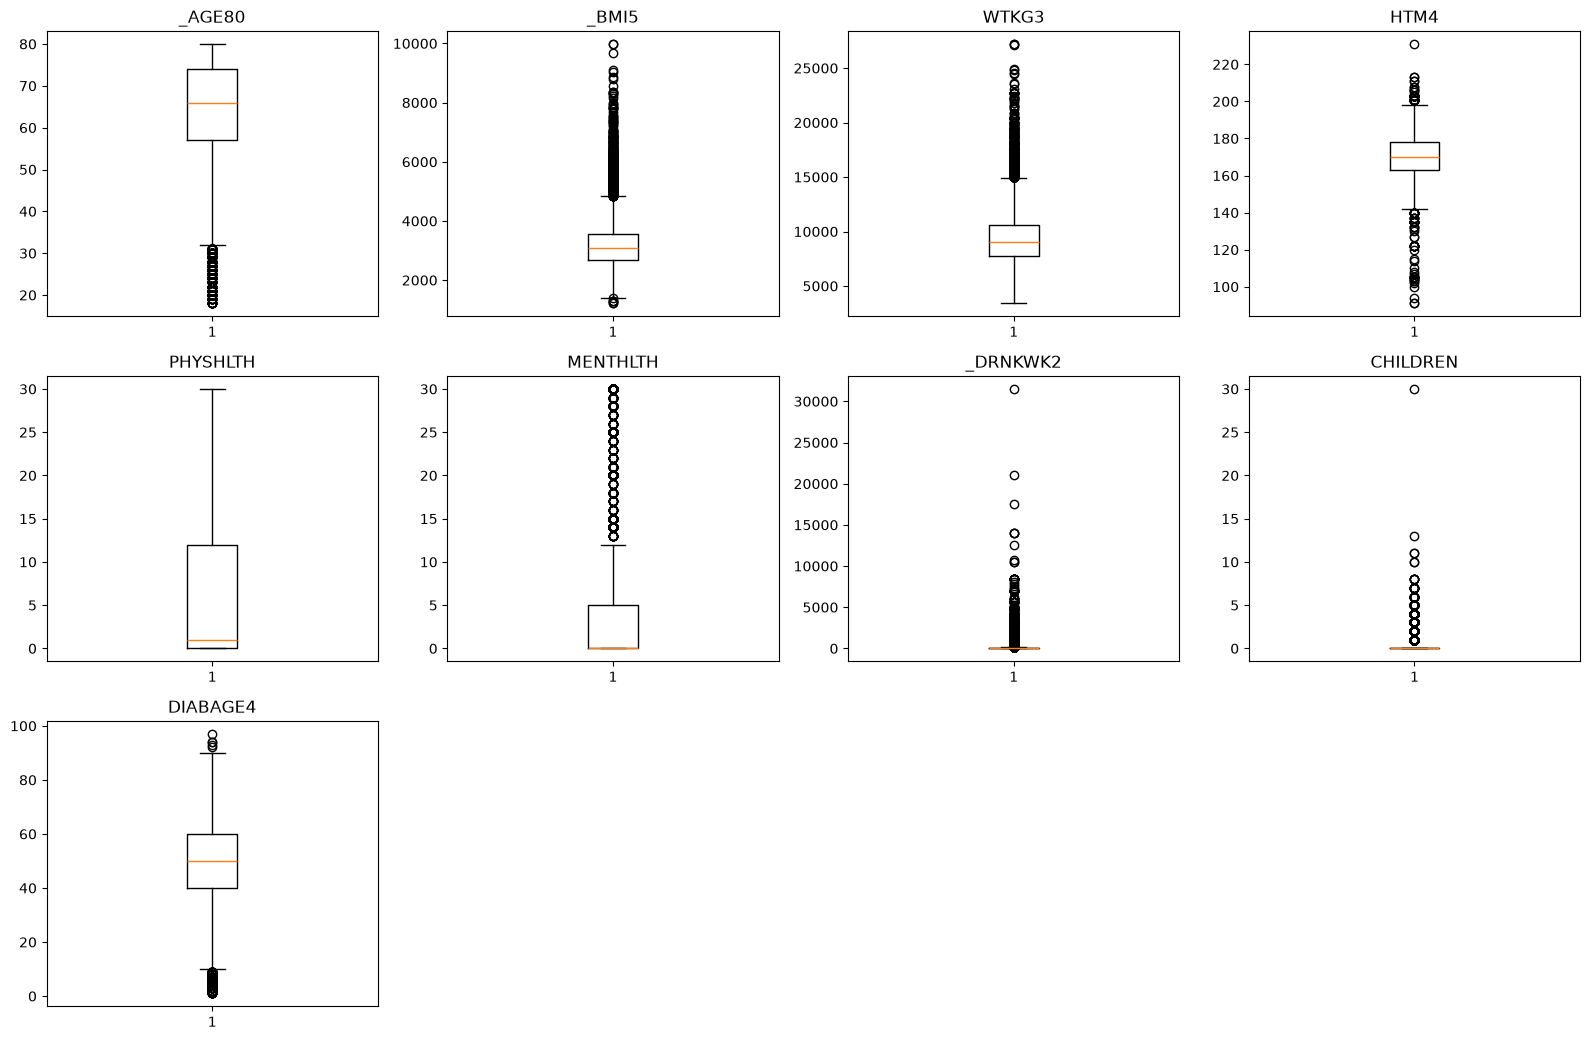

In [22]:
# %% Cek outlier (hanya fitur numerik kontinu)
import matplotlib.pyplot as plt

num_cols = ["_AGE80", "_BMI5", "WTKG3", "HTM4", "PHYSHLTH", "MENTHLTH",
            "SLEPTIM1", "_DRNKWK2", "CHILDREN", "DIABAGE4"]
num_cols = [c for c in num_cols if c in data.columns]

# %% Ringkasan outlier dengan metode IQR
rows = []
for c in num_cols:
    q1, q3 = data[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((data[c] < low) | (data[c] > high)).sum()
    rows.append({
        "fitur": c,
        "min": data[c].min(),
        "Q1": q1,
        "median": data[c].median(),
        "Q3": q3,
        "max": data[c].max(),
        "batas_bawah": round(low, 2),
        "batas_atas": round(high, 2),
        "jumlah_outlier": n_out,
        "persen_outlier": round(n_out / len(data) * 100, 2),
    })

outlier_df = pd.DataFrame(rows).sort_values("persen_outlier", ascending=False)
print(outlier_df.to_string(index=False))

# %% Visualisasi boxplot
n = len(num_cols)
ncols = 4
nrows = -(-n // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.5 * nrows))
axes = axes.flatten()

for ax, c in zip(axes, num_cols):
    ax.boxplot(data[c].dropna(), vert=True)
    ax.set_title(c)

for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

GENHLTH    -0.207024
CVDSTRK3    0.174989
_AGE80     -0.166037
DIFFWALK    0.164957
CHCKDNY2    0.164307
EMPLOY1    -0.163905
PHYSHLTH   -0.163005
CHCCOPD3    0.160709
HAVARTH4    0.121093
DEAF        0.106299
DIFFALON    0.104521
PERSDOC3   -0.104292
SEXVAR      0.103924
VETERAN3    0.103885
INCOME3     0.095532
PNEUVAC4    0.094479
_SMOKER3    0.088837
DIFFDRES    0.087237
BLIND       0.078863
EXERANY2   -0.066083
Name: _MICHD, dtype: float64


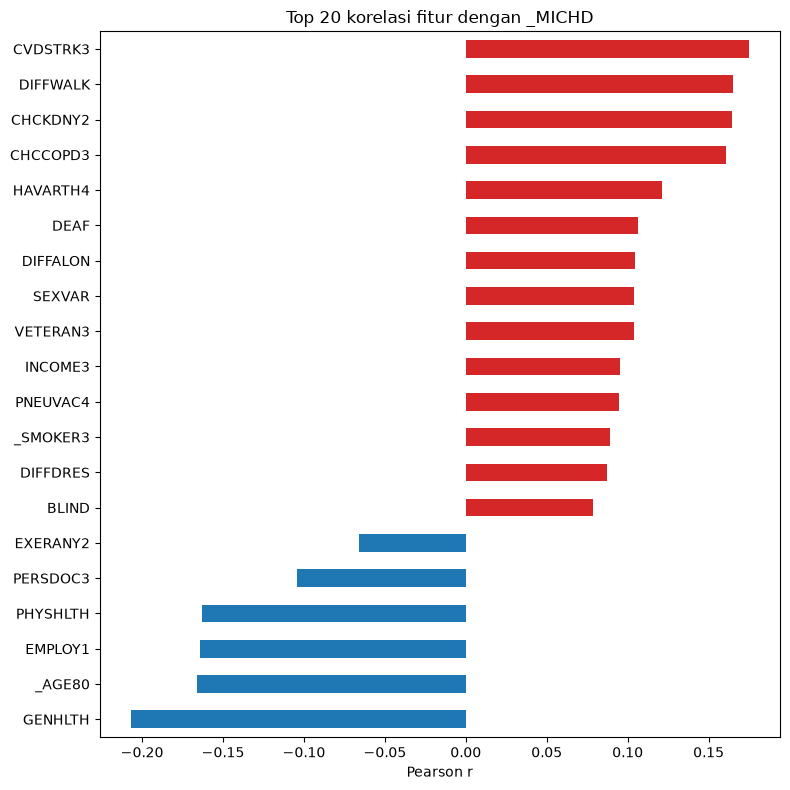

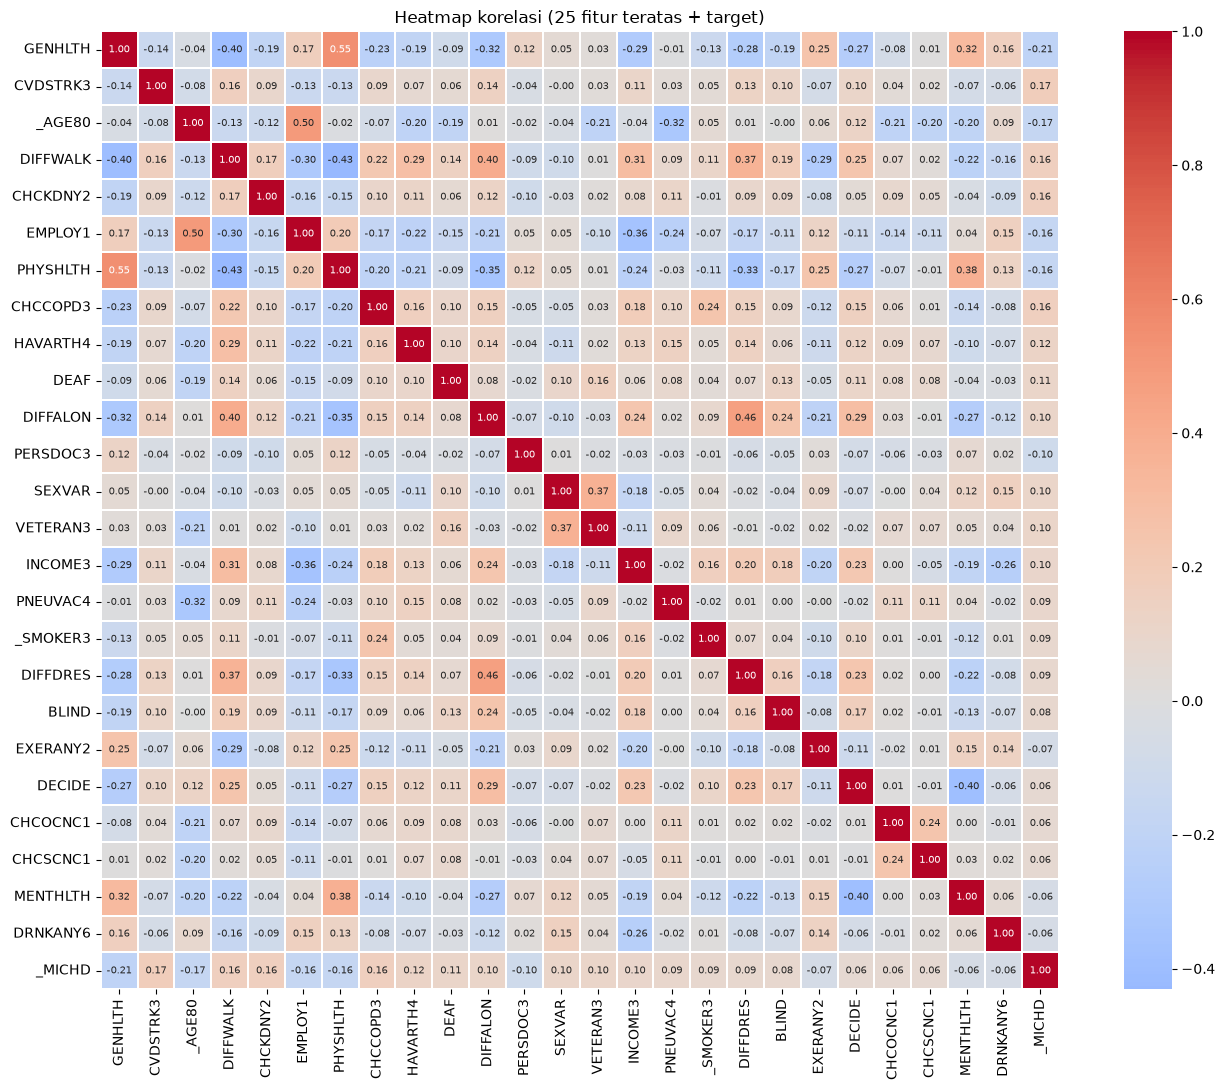

fitur_1 fitur_2      r
  _BMI5   WTKG3 0.8438


In [23]:
# %%
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Pastikan target numerik 0/1
df_corr = data.copy()
df_corr["_MICHD"] = df_corr["_MICHD"].astype(int)

corr = df_corr.corr(method="pearson", numeric_only=True)

# %%
# 1) Korelasi tiap fitur terhadap target (_MICHD)
target_corr = corr["_MICHD"].drop("_MICHD").sort_values(key=abs, ascending=False)
print(target_corr.head(20))

plt.figure(figsize=(8, 8))
top = target_corr.head(20).sort_values()
colors = ["tab:red" if v > 0 else "tab:blue" for v in top]
top.plot(kind="barh", color=colors)
plt.title("Top 20 korelasi fitur dengan _MICHD")
plt.xlabel("Pearson r")
plt.tight_layout(); plt.show()

# %%
# 2) Heatmap korelasi: 25 fitur teratas terhadap target + target
top_cols = target_corr.head(25).index.tolist() + ["_MICHD"]
plt.figure(figsize=(14, 11))
sns.heatmap(df_corr[top_cols].corr(), cmap="coolwarm", center=0,
            annot=True, fmt=".2f", annot_kws={"size": 7},
            square=True, linewidths=0.3)
plt.title("Heatmap korelasi (25 fitur teratas + target)")
plt.tight_layout(); plt.show()

# %%
# 3) Pasangan fitur dengan korelasi antar-fitur tinggi (|r| > 0.8)
feat_corr = corr.drop(index="_MICHD", columns="_MICHD")
upper = feat_corr.where(np.triu(np.ones(feat_corr.shape, dtype=bool), k=1))

high_pairs = (upper.stack()
                   .rename("r")
                   .reset_index()
                   .rename(columns={"level_0": "fitur_1", "level_1": "fitur_2"}))
high_pairs = high_pairs[high_pairs["r"].abs() > 0.8].sort_values("r", key=abs, ascending=False)
print(high_pairs.to_string(index=False))

In [24]:
# Cek value counts untuk semua fitur
for col in data.columns:
    print(f"\n{'=' * 60}")
    print(f"Fitur: {col}")
    print(f"Jumlah nilai unik: {data[col].nunique(dropna=False)}")
    print(f"{'=' * 60}")

    print(data[col].value_counts(dropna=False).to_string())


Fitur: _STATE
Jumlah nilai unik: 49
_STATE
53.0    1826
24.0    1522
39.0    1372
12.0    1242
31.0    1208
55.0    1140
36.0    1129
27.0    1082
18.0    1019
45.0    1013
23.0    1011
4.0     1006
19.0     842
13.0     831
48.0     830
20.0     819
26.0     818
6.0      765
15.0     709
51.0     676
34.0     628
9.0      623
49.0     622
54.0     580
29.0     569
30.0     568
46.0     552
47.0     550
40.0     538
5.0      531
1.0      529
25.0     519
22.0     504
33.0     500
8.0      471
17.0     456
44.0     439
50.0     435
41.0     430
28.0     427
38.0     421
16.0     398
56.0     389
10.0     358
37.0     336
2.0      326
35.0     316
32.0     198
11.0     181

Fitur: IYEAR
Jumlah nilai unik: 2
IYEAR
2023    32321
2024     1933

Fitur: SEXVAR
Jumlah nilai unik: 2
SEXVAR
1.0    18005
2.0    16249

Fitur: _AGE80
Jumlah nilai unik: 63
_AGE80
80.0    3597
70.0    1260
67.0    1183
72.0    1159
75.0    1150
65.0    1138
66.0    1102
68.0    1102
73.0    1089
69.0    1047
71.0   

In [25]:
data['CHILDREN'].value_counts()

CHILDREN
0.0     29136
1.0      2530
2.0      1588
3.0       634
4.0       232
5.0        73
6.0        34
7.0        16
8.0         5
10.0        2
11.0        2
30.0        1
13.0        1
Name: count, dtype: int64

In [26]:
# Konversi nilai ke satuan aktual
data["HTM4"] = data["HTM4"] / 100
data["WTKG3"] = data["WTKG3"] / 100
data["_BMI5"] = data["_BMI5"] / 100

In [27]:
data

,_STATE,IYEAR,SEXVAR,_AGE80,MARITAL,_EDUCAG,INCOME3,EMPLOY1,RENTHOM1,VETERAN3,...,DIFFWALK,DIFFDRES,DIFFALON,_SMOKER3,USENOW3,_DRNKWK2,_RFBING6,DRNKANY6,FLUSHOT7,PNEUVAC4
1,1.0,2023,2.0,76.0,3.0,3.0,7.0,8.0,1.0,2.0,...,1.0,2.0,1.0,4.0,2.0,4.700000e+01,1.0,1.0,2.0,1.0
3,1.0,2023,1.0,75.0,1.0,2.0,7.0,7.0,1.0,2.0,...,2.0,2.0,2.0,3.0,3.0,5.397605e-79,1.0,2.0,1.0,1.0
5,1.0,2023,2.0,80.0,2.0,2.0,5.0,7.0,2.0,2.0,...,1.0,2.0,1.0,3.0,3.0,5.397605e-79,1.0,2.0,1.0,1.0
6,1.0,2023,2.0,73.0,3.0,3.0,6.0,7.0,1.0,2.0,...,2.0,2.0,2.0,4.0,3.0,5.397605e-79,1.0,2.0,1.0,1.0
9,1.0,2023,2.0,73.0,3.0,3.0,6.0,7.0,1.0,1.0,...,1.0,2.0,2.0,4.0,3.0,7.000000e+01,1.0,1.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58245,56.0,2023,1.0,76.0,1.0,4.0,8.0,7.0,1.0,2.0,...,2.0,2.0,2.0,4.0,3.0,5.397605e-79,1.0,2.0,1.0,1.0
58246,56.0,2023,1.0,62.0,1.0,3.0,8.0,8.0,2.0,1.0,...,1.0,2.0,2.0,4.0,3.0,5.397605e-79,1.0,2.0,1.0,2.0
58247,56.0,2023,1.0,63.0,2.0,2.0,7.0,1.0,1.0,1.0,...,2.0,2.0,2.0,4.0,3.0,3.500000e+02,1.0,1.0,2.0,2.0
58250,56.0,2023,2.0,74.0,1.0,4.0,7.0,7.0,1.0,2.0,...,2.0,2.0,2.0,3.0,3.0,5.397605e-79,1.0,2.0,1.0,1.0


In [28]:
for col in data.columns:
    print(f"\n{'='*50}")
    print(f"Fitur: {col}")
    print(f"Jumlah nilai unik: {data[col].nunique()}")
    print("="*50)

    print(data[col].value_counts(dropna=False))


Fitur: _STATE
Jumlah nilai unik: 49
_STATE
53.0    1826
24.0    1522
39.0    1372
12.0    1242
31.0    1208
55.0    1140
36.0    1129
27.0    1082
18.0    1019
45.0    1013
23.0    1011
4.0     1006
19.0     842
13.0     831
48.0     830
20.0     819
26.0     818
6.0      765
15.0     709
51.0     676
34.0     628
9.0      623
49.0     622
54.0     580
29.0     569
30.0     568
46.0     552
47.0     550
40.0     538
5.0      531
1.0      529
25.0     519
22.0     504
33.0     500
8.0      471
17.0     456
44.0     439
50.0     435
41.0     430
28.0     427
38.0     421
16.0     398
56.0     389
10.0     358
37.0     336
2.0      326
35.0     316
32.0     198
11.0     181
Name: count, dtype: int64

Fitur: IYEAR
Jumlah nilai unik: 2
IYEAR
2023    32321
2024     1933
Name: count, dtype: int64

Fitur: SEXVAR
Jumlah nilai unik: 2
SEXVAR
1.0    18005
2.0    16249
Name: count, dtype: int64

Fitur: _AGE80
Jumlah nilai unik: 63
_AGE80
80.0    3597
70.0    1260
67.0    1183
72.0    1159
75.0   

In [29]:
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Helper
# ------------------------------------------------------------
def to_binary(df, col, yes, no):
    """Petakan yes -> 1, no -> 0. Semua kode lain (7, 9, dst) jadi NaN."""
    df[col] = df[col].map({yes: 1, no: 0})

def onehot(df, col, invalid=(7, 9), prefix=None):
    """
    1) Kode invalid (Don't know / Refused) -> NaN
    2) One-hot encoding
    3) Baris yang aslinya NaN tetap NaN di semua kolom dummy
       (bukan 0 semua)
    """
    prefix = prefix or col
    s = df[col].replace(list(invalid), np.nan).astype("Int64")
    mask = s.isna()
    dummies = pd.get_dummies(s, prefix=prefix, dtype=float)
    dummies[mask] = np.nan
    return pd.concat([df.drop(columns=col), dummies], axis=1)

# ------------------------------------------------------------
# BINARY (1 = Yes -> 1, 2 = No -> 0)
# ------------------------------------------------------------
# SEXVAR: 1 = Male, 2 = Female  ->  Male = 0, Female = 1
to_binary(data, "SEXVAR", yes=2, no=1)

# VETERAN3: 1 = Yes, 2 = No
to_binary(data, "VETERAN3", yes=1, no=2)

# _URBSTAT: 1 = Urban, 2 = Rural  ->  Urban = 1, Rural = 0
to_binary(data, "_URBSTAT", yes=1, no=2)

# FLUSHOT7, PNEUVAC4: 1 = Yes, 2 = No
for col in ["FLUSHOT7", "PNEUVAC4"]:
    to_binary(data, col, yes=1, no=2)

# _RFBING6: 1 = No, 2 = Yes, 9 = DK/Refused  (KEBALIKAN dari yang lain!)
to_binary(data, "_RFBING6", yes=2, no=1)

# Semua yang kodenya 1 = Yes, 2 = No
binary_features = [
    "MEDCOST1", "EXERANY2", "CVDSTRK3", "CHCSCNC1", "CHCOCNC1",
    "CHCCOPD3", "ADDEPEV3", "CHCKDNY2", "HAVARTH4",
    "DEAF", "BLIND", "DECIDE", "DIFFWALK", "DIFFDRES", "DIFFALON",
]
for col in binary_features:
    to_binary(data, col, yes=1, no=2)

# ------------------------------------------------------------
# ORDINAL
# ------------------------------------------------------------
# GENHLTH: 1 = Excellent ... 5 = Poor; 7, 9 -> NaN
data["GENHLTH"] = data["GENHLTH"].replace([7, 9], np.nan)

# ------------------------------------------------------------
# ONE-HOT (nominal)
# ------------------------------------------------------------
data = onehot(data, "MARITAL")
data = onehot(data, "EMPLOY1",   invalid=(9,))
data = onehot(data, "RENTHOM1",  invalid=(7, 9))
data = onehot(data, "_IMPRACE",  invalid=())          # 1-6, tidak ada kode invalid
data = onehot(data, "PERSDOC3",  invalid=(7, 9))
data = onehot(data, "_ASTHMS1",  invalid=(9,))
data = onehot(data, "_SMOKER3",  invalid=(9,))
data = onehot(data, "USENOW3",   invalid=(7, 9))

# ------------------------------------------------------------
# VERIFIKASI
# ------------------------------------------------------------
all_binary = (
    ["SEXVAR", "VETERAN3", "_URBSTAT", "FLUSHOT7", "PNEUVAC4", "_RFBING6"]
    + binary_features
)
for col in all_binary:
    vals = set(data[col].dropna().unique())
    assert vals <= {0, 1}, f"{col} punya nilai tak terduga: {vals}"
    print(f"{col:10s} ->", data[col].value_counts(dropna=False).to_dict())

SEXVAR     -> {0: 18005, 1: 16249}
VETERAN3   -> {0: 28079, 1: 6175}
_URBSTAT   -> {1: 28848, 0: 5406}
FLUSHOT7   -> {1: 20990, 0: 13264}
PNEUVAC4   -> {1: 22526, 0: 11728}
_RFBING6   -> {0: 32028, 1: 2226}
MEDCOST1   -> {0: 31681, 1: 2573}
EXERANY2   -> {1: 21561, 0: 12693}
CVDSTRK3   -> {0: 31103, 1: 3151}
CHCSCNC1   -> {0: 30645, 1: 3609}
CHCOCNC1   -> {0: 28407, 1: 5847}
CHCCOPD3   -> {0: 29581, 1: 4673}
ADDEPEV3   -> {0: 25578, 1: 8676}
CHCKDNY2   -> {0: 29515, 1: 4739}
HAVARTH4   -> {1: 17666, 0: 16588}
DEAF       -> {0: 29199, 1: 5055}
BLIND      -> {0: 31217, 1: 3037}
DECIDE     -> {0: 29417, 1: 4837}
DIFFWALK   -> {0: 23047, 1: 11207}
DIFFDRES   -> {0: 31572, 1: 2682}
DIFFALON   -> {0: 29944, 1: 4310}


In [30]:
data.info()
data["_MICHD"] = data["_MICHD"].map({1.0: 1, 2.0: 0}).astype(int)

<class 'pandas.DataFrame'>
Index: 34254 entries, 1 to 58251
Data columns (total 75 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   _STATE      34254 non-null  float64
 1   IYEAR       34254 non-null  int64  
 2   SEXVAR      34254 non-null  int64  
 3   _AGE80      34254 non-null  float64
 4   _EDUCAG     34254 non-null  float64
 5   INCOME3     34254 non-null  float64
 6   VETERAN3    34254 non-null  int64  
 7   CHILDREN    34254 non-null  float64
 8   _URBSTAT    34254 non-null  int64  
 9   _BMI5       34254 non-null  float64
 10  DIABETE4    34254 non-null  float64
 11  WTKG3       34254 non-null  float64
 12  HTM4        34254 non-null  float64
 13  MEDCOST1    34254 non-null  int64  
 14  CHECKUP1    34254 non-null  float64
 15  GENHLTH     34254 non-null  float64
 16  PHYSHLTH    34254 non-null  float64
 17  MENTHLTH    34254 non-null  float64
 18  EXERANY2    34254 non-null  int64  
 19  CVDSTRK3    34254 non-null  int64  
 20  

In [31]:
data['CHILDREN'].value_counts()

CHILDREN
0.0     29136
1.0      2530
2.0      1588
3.0       634
4.0       232
5.0        73
6.0        34
7.0        16
8.0         5
10.0        2
11.0        2
30.0        1
13.0        1
Name: count, dtype: int64

In [32]:
data = data[(data['CHILDREN'] < 30) | (data['CHILDREN'].isna())]
data = data.drop(columns=['WTKG3','HTM4'])

In [33]:
# 1 = minum alkohol dalam 30 hari terakhir, 0 = tidak
data['DRNKANY6'] = data['DRNKANY6'].map({1.0: 1, 2.0: 0})

print(data['DRNKANY6'].value_counts(dropna=False))

DRNKANY6
0    21170
1    13083
Name: count, dtype: int64


In [34]:
data.to_csv(r"C:\Users\s2\Documents\RKI\BRFSS\brfss2023_diabetes.csv", index=False)

In [35]:
data['_MICHD'].value_counts()

_MICHD
0    27304
1     6949
Name: count, dtype: int64

In [36]:
data['_MICHD'].value_counts()

_MICHD
0    27304
1     6949
Name: count, dtype: int64

In [37]:
data.info()

<class 'pandas.DataFrame'>
Index: 34253 entries, 1 to 58251
Data columns (total 73 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   _STATE      34253 non-null  float64
 1   IYEAR       34253 non-null  int64  
 2   SEXVAR      34253 non-null  int64  
 3   _AGE80      34253 non-null  float64
 4   _EDUCAG     34253 non-null  float64
 5   INCOME3     34253 non-null  float64
 6   VETERAN3    34253 non-null  int64  
 7   CHILDREN    34253 non-null  float64
 8   _URBSTAT    34253 non-null  int64  
 9   _BMI5       34253 non-null  float64
 10  DIABETE4    34253 non-null  float64
 11  MEDCOST1    34253 non-null  int64  
 12  CHECKUP1    34253 non-null  float64
 13  GENHLTH     34253 non-null  float64
 14  PHYSHLTH    34253 non-null  float64
 15  MENTHLTH    34253 non-null  float64
 16  EXERANY2    34253 non-null  int64  
 17  CVDSTRK3    34253 non-null  int64  
 18  CHCSCNC1    34253 non-null  int64  
 19  CHCOCNC1    34253 non-null  int64  
 20  